In [29]:
import vectorbt as vbt
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import mplfinance as mpf
from matplotlib.patches import Patch

In [39]:
def _to_pyfloat_like(x: pd.Series | pd.DataFrame) -> pd.Series:
    if isinstance(x, pd.DataFrame):
        xn = x.apply(pd.to_numeric, errors="coerce")
        best_col = xn.count().idxmax()
        s = xn[best_col]
    else:
        s = pd.to_numeric(x, errors="coerce")
    return s.astype(float)

def _select_symbol_slice(df: pd.DataFrame, symbol: str) -> pd.DataFrame:
    """From a MultiIndex (field, ticker) or (ticker, field), return a single-symbol OHLCV frame."""
    if not isinstance(df.columns, pd.MultiIndex):
        return df

    sym = (symbol or "").lower()
    lev0 = [str(x).lower() for x in df.columns.get_level_values(0)]
    lev1 = [str(x).lower() for x in df.columns.get_level_values(1)]
    cols_needed = {"open","high","low","close","volume"}

    # Case A: level 0 are fields, level 1 are tickers (your case: ('close','cams.ns'))
    if set(lev0) >= cols_needed:
        try:
            return df.xs(sym, level=1, axis=1, drop_level=True)
        except KeyError:
            # fall back to “first ticker” per field
            return df.groupby(level=0, axis=1).first()

    # Case B: level 0 are tickers, level 1 are fields
    if set(lev1) >= cols_needed:
        try:
            return df.xs(sym, level=0, axis=1, drop_level=True)
        except KeyError:
            # fall back to “first ticker” per field
            return df.groupby(level=1, axis=1).first()

    # Unknown shape -> return as-is
    return df

def prepare_ohlcv_for_mpf(df: pd.DataFrame, symbol: str | None = None) -> pd.DataFrame:
    """Select symbol from MultiIndex if needed, tz-naive index, unique cols, numeric floats, no-NaN OHLC."""
    out = _select_symbol_slice(df, symbol or "")
    out = out.copy()

    # datetime index tz-naive
    out.index = pd.to_datetime(out.index)
    if getattr(out.index, "tz", None) is not None:
        out.index = out.index.tz_localize(None)

    # normalize column names and drop dups
    out.columns = [str(c).strip().lower() for c in out.columns]
    out = out.loc[:, ~out.columns.duplicated(keep="first")]

    cols = ["open","high","low","close","volume"]
    missing = [c for c in cols if c not in out.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}; got {list(out.columns)}")

    for c in cols:
        out[c] = _to_pyfloat_like(out[c])

    out["volume"] = out["volume"].fillna(0.0)
    out = out.dropna(subset=["open","high","low","close"])
    return out

def align_to_trading_index(dt: pd.Timestamp, idx: pd.DatetimeIndex) -> pd.Timestamp | None:
    """Return the same date if present; else the next trading day in idx (or last prior if after range)."""
    if dt in idx:
        return dt
    pos = idx.searchsorted(dt, side="left")
    if pos < len(idx):
        return idx[pos]  # next trading day
    if len(idx) > 0:
        return idx[-1]   # past the end -> clamp to last bar
    return None

def to_series(x):
    """Return a 1-D Series from a vectorbt indicator field that may be Series or 1-col DataFrame."""
    if isinstance(x, pd.DataFrame):
        # take the first (and only) column
        return x.iloc[:, 0]
    return x  # already a Series

def load_data(symbol: str, years: int = 1) -> pd.DataFrame:
    """Download OHLCV data for a symbol from Yahoo Finance."""
    end = datetime.now()
    start = end - timedelta(days=365*years + 10)
    df = yf.download(symbol, start=start, end=end, auto_adjust=True, progress=False)
    if df.empty:
        raise ValueError(f"No data for {symbol}")
    df = df.rename(columns=str.lower)  # open, high, low, close, volume
    if getattr(df.index, "tz", None) is not None:
        df.index = df.index.tz_localize(None)
    return df

def compute_indicators(df: pd.DataFrame) -> dict:
    """Compute popular indicators with vectorbt."""
    close, high, low, vol = df['close'], df['high'], df['low'], df['volume']
    
    rsi = vbt.RSI.run(close, window=14)
    macd = vbt.MACD.run(close)
    bb   = vbt.BBANDS.run(close, window=20, alpha=2.0)
    ma20 = vbt.MA.run(close, window=20)
    ma50 = vbt.MA.run(close, window=50)
    atr  = vbt.ATR.run(high, low, close, window=14)
    
    return {
        "rsi": rsi,
        "macd": macd,
        "bb": bb,
        "ma20": ma20,
        "ma50": ma50,
        "atr": atr
    }

def detect_trend(df: pd.DataFrame, indicators: dict, mom_window: int = 20) -> pd.Series:
    """Simple trend regime detector using MA cross + momentum."""
    close = df['close']
    # Coerce MA outputs to Series
    ma20 = to_series(indicators['ma20'].ma).reindex(close.index)
    ma50 = to_series(indicators['ma50'].ma).reindex(close.index)
    ret = close.pct_change(mom_window)
    
    trend = pd.Series("Neutral", index=close.index, dtype="object")
    
    # Ensure boolean masks are Series and aligned with the index
    up_mask = (ma20 > ma50) & (ret > 0)
    dn_mask = (ma20 < ma50) & (ret < 0)
    
    # Convert to boolean Series if needed and fill NaNs
    if isinstance(up_mask, pd.DataFrame):
        up_mask = up_mask.iloc[:, 0]
    if isinstance(dn_mask, pd.DataFrame):
        dn_mask = dn_mask.iloc[:, 0]
    
    up_mask = up_mask.fillna(False)
    dn_mask = dn_mask.fillna(False)
    
    # Use .loc for safer indexing
    trend.loc[up_mask] = "Uptrend"
    trend.loc[dn_mask] = "Downtrend"
    
    return trend

def plot_candles(df: pd.DataFrame, indicators: dict, symbol: str):
    """Plot candlestick chart with MAs and Bollinger Bands (vectorbt)."""
    close = df['close']
    ma20 = to_series(indicators['ma20'].ma).reindex(close.index)
    ma50 = to_series(indicators['ma50'].ma).reindex(close.index)
    bb = indicators['bb']
    bb_mid   = to_series(bb.middle).reindex(close.index)
    bb_upper = to_series(bb.upper).reindex(close.index)
    bb_lower = to_series(bb.lower).reindex(close.index)
    
    plt.figure(figsize=(12,6))
    plt.plot(close.index, close, label="Close")
    plt.plot(ma20.index, ma20, label="MA20")
    plt.plot(ma50.index, ma50, label="MA50")
    plt.fill_between(bb_mid.index, bb_lower, bb_upper, alpha=0.2, label="BBands")
    plt.title(f"{symbol} — Candles + MA20/MA50 + BBands")
    plt.legend()
    plt.show()

def plot_momentum(indicators: dict, symbol: str):
    """Plot RSI and MACD charts."""
    rsi = indicators['rsi']
    macd = indicators['macd']
    
    # RSI plot
    plt.figure(figsize=(12,3))
    rsi_series = to_series(rsi.rsi)
    plt.plot(rsi_series.index, rsi_series, label="RSI(14)")
    plt.axhline(70, linestyle="--", color="red")
    plt.axhline(30, linestyle="--", color="green")
    plt.title(f"{symbol} RSI")
    plt.legend()
    plt.show()
    
    # MACD plot
    plt.figure(figsize=(12,3))
    macd_line = to_series(macd.macd)
    signal_line = to_series(macd.signal)
    hist_line = to_series(macd.hist)
    
    plt.plot(macd_line.index, macd_line, label="MACD")
    plt.plot(signal_line.index, signal_line, label="Signal")
    plt.bar(hist_line.index, hist_line, label="Hist", color="gray", alpha=0.6)
    plt.title(f"{symbol} MACD")
    plt.legend()
    plt.show()

def analyze_symbol(symbol: str = "CAMS.NS", years: int = 1):
    # Load data
    df = load_data(symbol, years)
    print(f"Loaded {len(df)} bars for {symbol}")
    
    # Indicators
    ind = compute_indicators(df)
    
    # Trend
    trend = detect_trend(df, ind)
    print(f"Latest trend: {trend.iloc[-1]}")
    
    # Plots
    plot_candles(df, ind, symbol)
    plot_momentum(ind, symbol)
    
    return df, ind, trend

Loaded 258 bars for CAMS.NS
Latest trend: Neutral


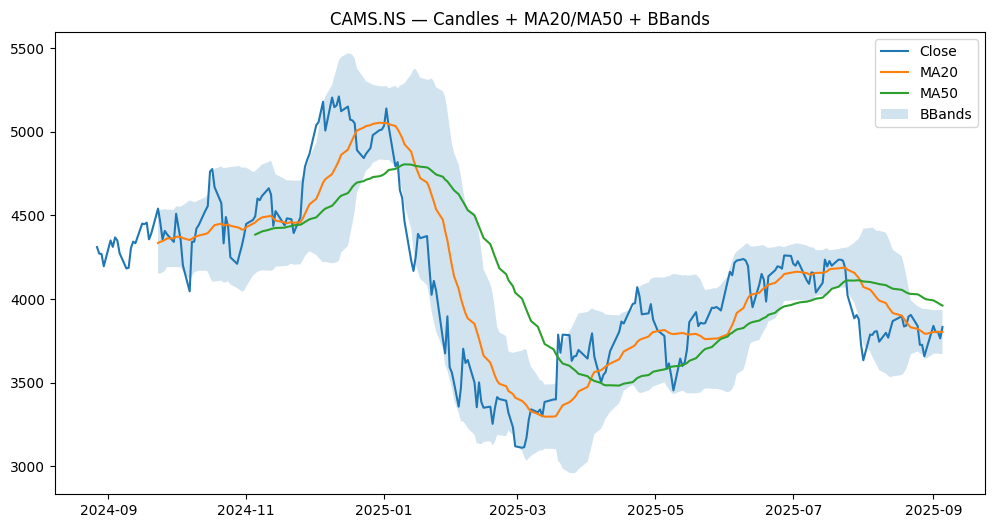

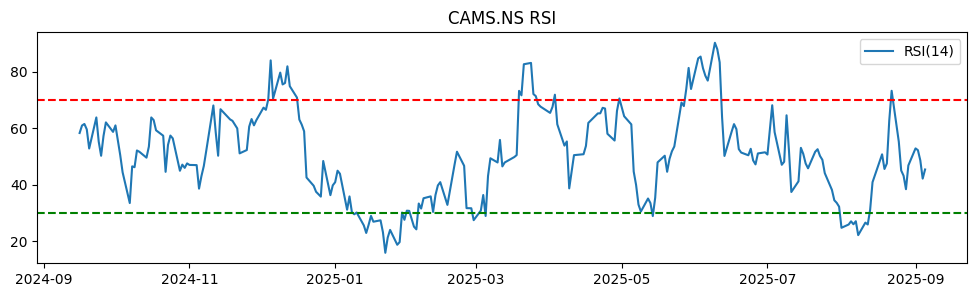

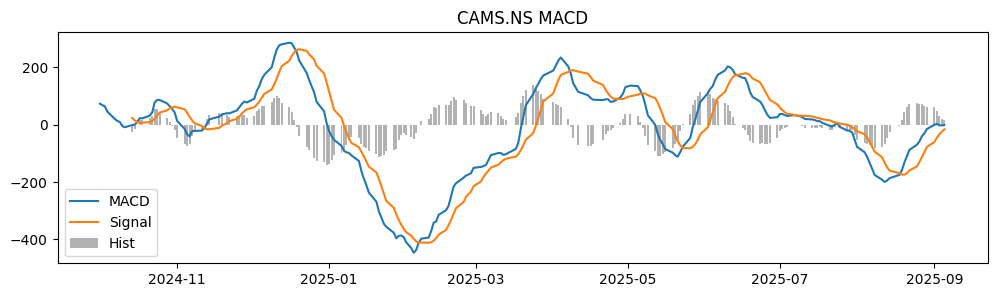

In [32]:
df, ind, trend = analyze_symbol("CAMS.NS", years=1)

In [62]:
def load_events(symbol: str, ohlcv: pd.DataFrame) -> pd.DataFrame:
    """
    Returns tidy events with columns: date, type, label
    - Dividends: label 'D +x.x%' where x = dividend/prev_close*100 on ex-div date
    - Splits/Bonus: 'S post:pre' based on Yahoo ratio (post/pre)
    - Earnings: 'E' using get_earnings_dates
    """
    t = yf.Ticker(symbol)
    rows = []
    
    # Make tz-naive view of OHLCV index for comparisons
    px = ohlcv.copy()
    if getattr(px.index, "tz", None) is not None:
        px.index = px.index.tz_localize(None)
    
    # Dividends (ex-dividend dates)
    try:
        div = t.dividends
        if div is not None and len(div) > 0:
            # Make timezone-naive
            div.index = pd.to_datetime(div.index).tz_localize(None)
            
            for dt, val in div.items():
                # Find the closest previous trading day
                prev_close = None
                try:
                    # Find all dates before the dividend date
                    before_dates = px.index[px.index < dt]
                    if len(before_dates) > 0:
                        # Get the most recent trading day before dividend
                        prev_date = before_dates[-1]
                        prev_close = px.loc[prev_date, "close"]
                        
                        # Calculate dividend yield percentage
                        if pd.notna(prev_close) and prev_close > 0:
                            pct = float(val / prev_close * 100)
                            label = f"D {pct:.1f}%"
                        else:
                            label = "D"
                    else:
                        label = "D"
                except Exception:
                    label = "D"
                
                rows.append({"date": dt, "type": "DIVIDEND", "label": label})
                
    except Exception as e:
        print(f"Error loading dividends: {e}")
    
    # Splits / Bonus (Yahoo ratio is post/pre, e.g., 5.0 == 5-for-1)
    try:
        sp = t.splits
        if sp is not None and len(sp) > 0:
            sp.index = pd.to_datetime(sp.index).tz_localize(None)
            for dt, ratio in sp.items():
                lab = "S"
                try:
                    r = float(ratio)
                    if r >= 1:
                        lab = f"S {int(r)}:1"
                    else:
                        lab = f"S 1:{int(round(1/r))}"
                except Exception:
                    pass
                rows.append({"date": dt, "type": "SPLIT", "label": lab})
    except Exception as e:
        print(f"Error loading splits: {e}")
    
    # Earnings (earnings announcement dates)
    try:
        ed = t.get_earnings_dates(limit=48)
        if ed is not None and len(ed) > 0:
            # DataFrame indexed by date (could be tz-aware); just coerce
            ed_idx = pd.to_datetime(ed.index).tz_localize(None)
            for dt in ed_idx:
                rows.append({"date": dt, "type": "EARNINGS", "label": "E"})
    except Exception as e:
        print(f"Error loading earnings: {e}")
    
    ev = pd.DataFrame(rows)
    if ev.empty:
        return ev
    
    # Keep only within price range and sort
    start, end = px.index.min(), px.index.max()
    ev = ev[(ev["date"] >= start) & (ev["date"] <= end)].sort_values("date").reset_index(drop=True)
    return ev


def _group_event_dates(events: pd.DataFrame, idx: pd.DatetimeIndex) -> dict[str, list[pd.Timestamp]]:
    if events is None or events.empty:
        return {"DIVIDEND": [], "SPLIT": [], "EARNINGS": []}
    out = {"DIVIDEND": [], "SPLIT": [], "EARNINGS": []}
    for _, r in events.iterrows():
        d = align_to_trading_index(pd.Timestamp(r["date"]), idx)
        if d is None:
            continue
        t = str(r["type"]).upper()
        if t in out:
            out[t].append(d)
    # de-dup & sort
    for k in out:
        out[k] = sorted(pd.unique(out[k]))
    return out

def plot_candles_with_events(df_raw: pd.DataFrame, indicators: dict, symbol: str, events: pd.DataFrame | None):
    df = prepare_ohlcv_for_mpf(df_raw, symbol).sort_index()
    # Reindex indicators to sanitized df index
    ma20 = to_series(indicators['ma20'].ma).reindex(df.index)
    ma50 = to_series(indicators['ma50'].ma).reindex(df.index)
    bb   = indicators['bb']
    bb_mid   = to_series(bb.middle).reindex(df.index)
    bb_upper = to_series(bb.upper).reindex(df.index)
    bb_lower = to_series(bb.lower).reindex(df.index)
    
    # Prepare event markers as additional plots
    event_plots = []
    if events is not None and not events.empty:
        # Create series for each event type
        dividend_events = pd.Series(index=df.index, dtype=float)
        split_events = pd.Series(index=df.index, dtype=float)
        earnings_events = pd.Series(index=df.index, dtype=float)
        
        hi = df['high']
        price_range = hi.max() - hi.min()
        bubble_height = price_range * 0.03  # 3% above high
        
        for _, r in events.iterrows():
            event_date = pd.Timestamp(r['date'])
            d_aligned = align_to_trading_index(event_date, df.index)
            
            if d_aligned is None:
                # Find closest trading day
                try:
                    closest_idx = df.index.get_indexer([event_date], method='nearest')[0]
                    d_aligned = df.index[closest_idx]
                except:
                    continue
            
            if d_aligned not in df.index:
                continue
                
            # Position bubble above the high of that day
            bubble_y = float(hi.loc[d_aligned]) + bubble_height
            
            t = r['type']
            if t == "DIVIDEND":
                dividend_events.loc[d_aligned] = bubble_y
            elif t in ["SPLIT", "BONUS"]:
                split_events.loc[d_aligned] = bubble_y
            elif t == "EARNINGS":
                earnings_events.loc[d_aligned] = bubble_y
        
        # Add event markers as scatter plots
        if not dividend_events.dropna().empty:
            event_plots.append(mpf.make_addplot(dividend_events, type='scatter', markersize=200, 
                                               color='#22c55e', alpha=0.9, secondary_y=False))
        if not split_events.dropna().empty:
            event_plots.append(mpf.make_addplot(split_events, type='scatter', markersize=200, 
                                               color='#f97316', alpha=0.9, secondary_y=False))
        if not earnings_events.dropna().empty:
            event_plots.append(mpf.make_addplot(earnings_events, type='scatter', markersize=250, 
                                               color='#8b5cf6', alpha=0.9, secondary_y=False))
    
    # Combine all addplots
    ap = [
        mpf.make_addplot(ma20, color='tab:orange', width=1.2),
        mpf.make_addplot(ma50, color='tab:green',  width=1.2),
        mpf.make_addplot(bb_upper, color='lightblue', width=0.8),
        mpf.make_addplot(bb_lower, color='lightblue', width=0.8),
    ] + event_plots
    
    # Create the plot
    fig, axes = mpf.plot(
        df[['open','high','low','close','volume']],
        type='candle',
        style='yahoo',
        addplot=ap,
        volume=True,
        returnfig=True,
        figratio=(16,9),
        title=f"{symbol} — Candles + MA20/50 + BBands + Events",
        fill_between=dict(y1=bb_lower.values, y2=bb_upper.values, alpha=0.25)
    )
    ax = axes[0]
    
    # Add text labels for events
    if events is not None and not events.empty:
        hi = df['high']
        price_range = hi.max() - hi.min()
        
        for _, r in events.iterrows():
            event_date = pd.Timestamp(r['date'])
            d_aligned = align_to_trading_index(event_date, df.index)
            
            if d_aligned is None:
                try:
                    closest_idx = df.index.get_indexer([event_date], method='nearest')[0]
                    d_aligned = df.index[closest_idx]
                except:
                    continue
            
            if d_aligned not in df.index:
                continue
            
            # Get the position in the dataframe for x-coordinate
            x_pos = df.index.get_loc(d_aligned)
            yval = float(hi.loc[d_aligned]) + (price_range * 0.03)
            
            t = r['type']
            txt = r.get('label', t)
            
            # Add letter inside bubble
            if t == "DIVIDEND":
                symbol_char = "D"
                text_color = "white"
            elif t in ["SPLIT", "BONUS"]:
                symbol_char = "S" 
                text_color = "white"
            elif t == "EARNINGS":
                symbol_char = "E"
                text_color = "white"
            else:
                symbol_char = "?"
                text_color = "white"
            
            # Add text on the bubble
            ax.text(x_pos, yval, symbol_char, ha='center', va='center',
                   color=text_color, fontsize=9, fontweight='bold', zorder=15)
        
        # Create custom legend
        from matplotlib.patches import Patch
        handles = [
            Patch(color="#22c55e", label="Dividend"),
            Patch(color="#f97316", label="Split/Bonus"), 
            Patch(color="#8b5cf6", label="Earnings"),
            Patch(color="lightblue", label="BBands"),
        ]
        ax.legend(handles=handles, loc="upper left", framealpha=0.9)
    
    mpf.show()

In [63]:
events = load_events("CAMS.NS", df)

In [64]:
print(events)

                 date      type label
0 2024-10-28 13:45:00  EARNINGS     E
1 2024-11-08 00:00:00  DIVIDEND     D
2 2025-01-29 15:26:00  EARNINGS     E
3 2025-02-07 00:00:00  DIVIDEND     D
4 2025-05-05 18:49:00  EARNINGS     E
5 2025-05-06 11:00:00  EARNINGS     E
6 2025-07-15 00:00:00  DIVIDEND     D
7 2025-08-08 00:00:00  DIVIDEND     D


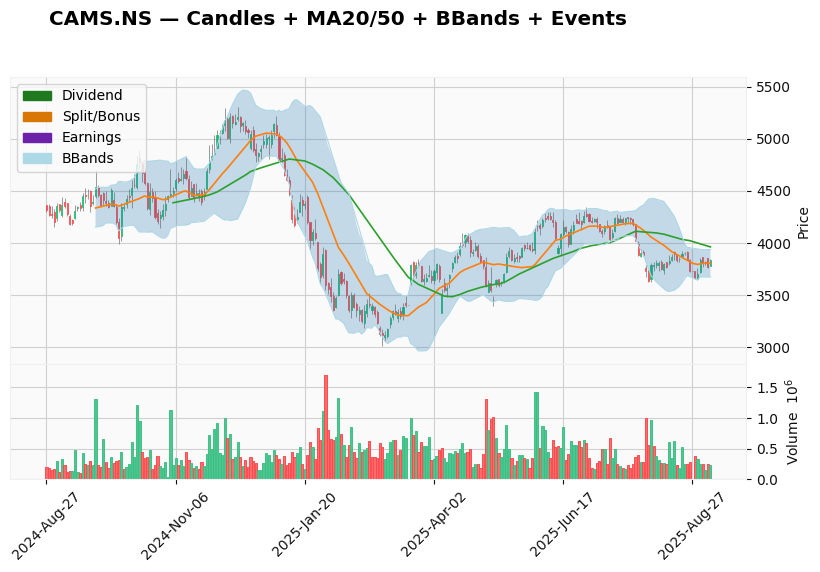

In [48]:
plot_candles_with_events(df, ind, "CAMS.NS", events)

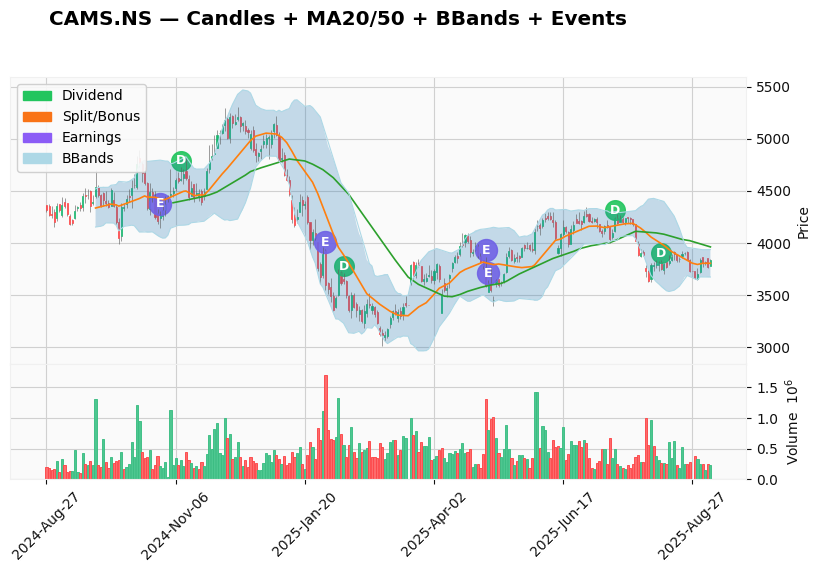

In [65]:
plot_candles_with_events(df, ind, "CAMS.NS", events)

=== Testing event loading for CAMS.NS ===

Final result:
Events shape: (8, 3)
Events:
                 date      type label
0 2024-10-28 13:45:00  EARNINGS     E
1 2024-11-08 00:00:00  DIVIDEND     D
2 2025-01-29 15:26:00  EARNINGS     E
3 2025-02-07 00:00:00  DIVIDEND     D
4 2025-05-05 18:49:00  EARNINGS     E
5 2025-05-06 11:00:00  EARNINGS     E
6 2025-07-15 00:00:00  DIVIDEND     D
7 2025-08-08 00:00:00  DIVIDEND     D
